# Where Is My Train or Bus?
## The inspection paradox at the bus stop

**Lecture 8: Contexts Matter** (companion to slides 22 to 25)

You have probably had this experience: the transit authority says a bus comes every 10 minutes, yet you seem to wait longer than 5 minutes much more often than you should. This notebook shows that you are not imagining it, and that neither you nor the transit authority is wrong. You are measuring different things.

The transit authority counts **every gap between buses once**. A rider who shows up at a random time is **more likely to land in a long gap, simply because long gaps take up more of the clock**. That is the inspection paradox (also called length-biased sampling, or the waiting-time paradox), the same effect behind class sizes, the friendship paradox and prison sentences in today's lecture.

**What you will do in this notebook**

1. Simulate perfectly regular buses and confirm the "obvious" 5-minute wait.
2. Draw a timeline that shows why random riders over-sample long gaps.
3. Derive and test the formula for the average wait.
4. Reproduce the bus-bunching worked example from slide 25 (5.0 versus 8.2 minutes).
5. Compare the operator's view and the passenger's view of the Boston MBTA Red Line example (slides 23 and 24).
6. Undo the bias by reweighting, as we did for class sizes.
7. See how waiting time grows with the variability of the gaps.
8. Explore what real-time tracking apps change, and what they don't.

**How to use it.** Run the cells from top to bottom (in Jupyter: *Kernel, Restart & Run All*). Text cells explain what each code cell does and how to read its output. Exercises at the end ask you to change the code and predict the result before you run it.

**Requirements.** Python 3 with `numpy`, `matplotlib` and `scipy`.

## 1. Setup

We import three libraries:

* `numpy` for random numbers and arrays,
* `matplotlib` for plots,
* `scipy.stats.gaussian_kde` to draw smooth distribution curves like the ones on the slides.

We also fix the **random seed**, so everyone in the class gets exactly the same "random" results, and define the colors used throughout: orange for the operator's view (each gap counted once), blue for the passenger's view and green for a reweighted, corrected view. These match the colors on the slides.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

rng = np.random.default_rng(seed=8)   # fixed seed for reproducible results

OPERATOR = "#D9822B"    # orange: each gap counted once (the operator's view)
PASSENGER = "#1F5FA8"   # blue: gaps as experienced by riders arriving at random
CORRECTED = "#2E8B57"   # green: passenger data reweighted by 1/gap

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
print("Setup complete.")

Setup complete.


## 2. Helper functions

Everything in this notebook comes down to three small steps, so we write them once as functions:

1. **`bus_times_from_gaps`** turns a list of gaps (minutes between consecutive buses) into a list of arrival times. If the gaps are 10, 10, 10, the buses arrive at minutes 10, 20, 30 (we assume one bus has just left at minute 0).
2. **`random_riders`** creates riders who show up at the stop at uniformly random times between minute 0 and the last bus. "Uniformly random" means a rider is equally likely to arrive at any moment; they are not looking at a schedule or an app.
3. **`waits_and_gaps`** finds, for each rider, the **next** bus after they arrive. It returns how long each rider waited, and how long the gap was that they landed in.

`np.searchsorted` does the heavy lifting in step 3. For each arrival time, it finds the position of the first bus that comes at or after that time.

In [2]:
def bus_times_from_gaps(gaps):
    # Arrival times of buses, given the gaps between them (minutes).
    return np.cumsum(gaps)

def random_riders(bus_times, n_riders, rng=rng):
    # Riders arriving at uniformly random times between minute 0 and the last bus.
    return rng.uniform(0, bus_times[-1], size=n_riders)

def waits_and_gaps(bus_times, rider_times):
    # For each rider: how long until the next bus, and the length of the gap they landed in.
    idx = np.searchsorted(bus_times, rider_times)         # index of the next bus
    next_bus = bus_times[idx]
    prev_bus = np.where(idx > 0, bus_times[idx - 1], 0.0)  # the bus before (or minute 0)
    return next_bus - rider_times, next_bus - prev_bus

## 3. The ideal case: perfectly regular buses

Start with the schedule the transit authority promises: a bus **exactly** every 10 minutes for 10 hours (60 buses). We send 100,000 riders to the stop at random times.

**Prediction before you run it.** If buses come every 10 minutes and you arrive at a random moment, sometimes you just miss one (wait almost 10) and sometimes one is pulling in (wait almost 0). On average you should wait half the gap: **5 minutes**.

In [3]:
regular_gaps = np.full(60, 10.0)                 # 60 gaps of exactly 10 minutes
regular_buses = bus_times_from_gaps(regular_gaps)
riders = random_riders(regular_buses, 100_000)
regular_waits, regular_seen = waits_and_gaps(regular_buses, riders)

print(f"Average gap between buses (operator's view): {regular_gaps.mean():.2f} min")
print(f"Average gap riders landed in:                 {regular_seen.mean():.2f} min")
print(f"Average wait for a random rider:              {regular_waits.mean():.2f} min")

Average gap between buses (operator's view): 10.00 min
Average gap riders landed in:                 10.00 min
Average wait for a random rider:              5.00 min


**How to read this.** All three numbers agree with intuition. When every gap is the same length there is nothing to over-sample: every rider lands in a 10-minute gap, and on average waits 5 minutes.

This is the "no variation, no paradox" case from slide 16: when the spread of gap lengths is zero, the operator and the rider see the same thing. Everything interesting happens once gaps start to vary.

## 4. Picture it: why long gaps catch more riders

Real buses are not perfectly regular. Below we compare two hours of service with the **same number of buses and the same average gap** (10 minutes):

* **Top row:** regular service, a bus every 10 minutes.
* **Bottom row:** irregular service with gaps of 3, 17, 6, 14, 2 and 18 minutes. These still add up to 60 minutes per hour, so the average gap is still 10.

Vertical lines are bus arrivals. Each dot is a rider who arrived at a random time, colored by the gap they landed in. Watch how the dots pile up in the long gaps on the bottom row.

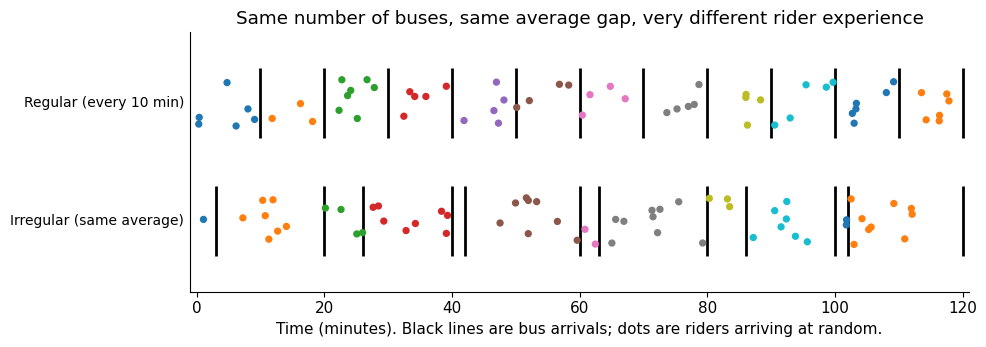

In [4]:
irregular_pattern = np.array([3, 17, 6, 14, 2, 18], dtype=float)  # sums to 60, mean 10
rows = {
    "Regular (every 10 min)": np.tile([10.0] * 6, 2),
    "Irregular (same average)": np.tile(irregular_pattern, 2),
}

fig, ax = plt.subplots(figsize=(10, 3.6))
palette = plt.cm.tab10.colors
for row, (label, gaps) in enumerate(rows.items()):
    y = 1 - row                                    # top row at y=1, bottom row at y=0
    buses = bus_times_from_gaps(gaps)
    ax.vlines(buses, y - 0.3, y + 0.3, color="black", lw=2)
    t = random_riders(buses, 60)                   # 60 random riders over 2 hours
    idx = np.searchsorted(buses, t)
    jitter = rng.uniform(-0.2, 0.2, size=t.size)
    ax.scatter(t, y + jitter, s=18, c=[palette[i % 10] for i in idx], zorder=3)
    ax.text(-2, y, label, ha="right", va="center", fontsize=10)

ax.set_xlim(-1, 121)
ax.set_ylim(-0.6, 1.6)
ax.set_yticks([])
ax.set_xlabel("Time (minutes). Black lines are bus arrivals; dots are riders arriving at random.")
ax.set_title("Same number of buses, same average gap, very different rider experience")
ax.grid(False)
plt.tight_layout()
plt.show()

Let's put numbers on that picture. For the irregular pattern, the table compares two things for each gap length:

* **Share of gaps:** each of the six gaps counts once (1 in 6, or about 17% each). This is how the operator counts.
* **Share of riders:** the fraction of random riders who land in that gap. Because riders arrive uniformly in time, this equals the gap's share of the total time: gap length divided by 60.

The 18-minute gap is only one gap in six, but it catches 30% of the riders.

In [5]:
total = irregular_pattern.sum()
print(f"{'Gap (min)':>10} {'Share of gaps':>15} {'Share of riders':>17}")
for g in sorted(irregular_pattern):
    print(f"{g:>10.0f} {1/len(irregular_pattern):>15.0%} {g/total:>17.0%}")

buses = bus_times_from_gaps(np.tile(irregular_pattern, 100))
waits, seen = waits_and_gaps(buses, random_riders(buses, 200_000))
print()
print(f"Operator's average gap:        {irregular_pattern.mean():.2f} min")
print(f"Average gap riders landed in:  {seen.mean():.2f} min")
print(f"Average wait (simulated):      {waits.mean():.2f} min   (regular service: 5.00 min)")

 Gap (min)   Share of gaps   Share of riders
         2             17%                3%
         3             17%                5%
         6             17%               10%
        14             17%               23%
        17             17%               28%
        18             17%               30%

Operator's average gap:        10.00 min
Average gap riders landed in:  14.29 min
Average wait (simulated):      7.14 min   (regular service: 5.00 min)


## 5. The math behind it

The picture and the table suggest a rule: **a rider's chance of landing in a gap is proportional to the gap's length.** That is exactly the length-biased sampling from slides 15 and 16. Write $f(x)$ for the operator's distribution of gap lengths, with mean $\mu$ and variance $\sigma^2$. Then:

**Distribution of gaps riders land in.** Long gaps are over-represented in proportion to their length:

$$f_{\text{rider}}(x) \;\propto\; x \, f(x) \qquad\text{that is,}\qquad f_{\text{rider}}(x) = \frac{x\, f(x)}{\mu}$$

(The symbol $\propto$ means "is proportional to." Dividing by $\mu$ just makes the probabilities add up to 1.)

**Average gap riders land in.**

$$\mu_{\text{rider}} = \frac{E[X^2]}{E[X]} = \mu + \frac{\sigma^2}{\mu}$$

**Average wait.** Within whichever gap you land in, your arrival is equally likely to be anywhere, so on average you wait half of it:

$$E[\text{wait}] = \frac{\mu_{\text{rider}}}{2} = \frac{E[X^2]}{2\,E[X]} = \frac{1}{2}\left(\mu + \frac{\sigma^2}{\mu}\right)$$

Two consequences to keep in mind:

* If $\sigma = 0$ (perfectly regular buses), the wait is $\mu/2$: 5 minutes for a 10-minute schedule.
* The extra wait grows with $\sigma^2$, the **square** of the spread. Doubling the irregularity roughly quadruples the extra waiting.

The functions below compute these quantities directly from a list of gaps. We check them against the simulation from Section 4.

In [6]:
def operator_mean_gap(gaps):
    # Each gap counted once.
    return np.mean(gaps)

def rider_mean_gap(gaps):
    # Gaps weighted by their length: E[X^2] / E[X].
    gaps = np.asarray(gaps, dtype=float)
    return np.sum(gaps**2) / np.sum(gaps)

def expected_wait(gaps):
    # Average wait for a rider arriving at a uniformly random time: E[X^2] / (2 E[X]).
    return rider_mean_gap(gaps) / 2

mu, sigma = irregular_pattern.mean(), irregular_pattern.std()
print("Irregular pattern from Section 4")
print(f"  mu = {mu:.2f}, sigma = {sigma:.2f}")
print(f"  mu + sigma^2/mu       = {mu + sigma**2/mu:.2f} min  (formula)")
print(f"  rider_mean_gap(gaps)  = {rider_mean_gap(irregular_pattern):.2f} min  (formula, via E[X^2]/E[X])")
print(f"  simulated             = {seen.mean():.2f} min")
print(f"  expected_wait(gaps)   = {expected_wait(irregular_pattern):.2f} min  vs simulated {waits.mean():.2f} min")

Irregular pattern from Section 4
  mu = 10.00, sigma = 6.56
  mu + sigma^2/mu       = 14.30 min  (formula)
  rider_mean_gap(gaps)  = 14.30 min  (formula, via E[X^2]/E[X])
  simulated             = 14.29 min
  expected_wait(gaps)   = 7.15 min  vs simulated 7.14 min


The formula and the simulation agree (small differences are random noise from the simulation). From here on we can use the formula when we want an exact answer and the simulation when we want to see the whole distribution.

## 6. Worked example: bus bunching (slide 25)

Bus bunching is a common real-world cause of irregular gaps. A bus that falls a little behind finds more people waiting at each stop, so boarding takes longer and it falls further behind. The bus behind it finds empty stops and catches up. Soon the two travel as a pair.

Slide 25 uses these hypothetical numbers for a route scheduled every 10 minutes:

* **On schedule:** every gap is 10 minutes.
* **Bunched:** buses arrive in pairs, so gaps alternate between **2 minutes** and **18 minutes**.

The average gap is still $(2 + 18)/2 = 10$ minutes. On paper, nothing has changed. Let's see what riders experience.

In [7]:
on_schedule = np.full(60, 10.0)
bunched = np.tile([2.0, 18.0], 30)        # 2, 18, 2, 18, ... (60 gaps)

for name, gaps in [("On schedule", on_schedule), ("Bunched", bunched)]:
    buses = bus_times_from_gaps(gaps)
    w, s = waits_and_gaps(buses, random_riders(buses, 200_000))
    print(f"{name:<12}  operator's average gap = {operator_mean_gap(gaps):5.2f} min   "
          f"expected wait = {expected_wait(gaps):4.2f} min   simulated wait = {w.mean():4.2f} min")

share_long = 18 / (2 + 18)
increase = expected_wait(bunched) / expected_wait(on_schedule) - 1
print()
print(f"Share of riders who land in an 18-minute gap: {share_long:.0%}")
print(f"Increase in average wait from bunching:       {increase:.0%}")

On schedule   operator's average gap = 10.00 min   expected wait = 5.00 min   simulated wait = 5.00 min
Bunched       operator's average gap = 10.00 min   expected wait = 8.20 min   simulated wait = 8.20 min

Share of riders who land in an 18-minute gap: 90%
Increase in average wait from bunching:       64%


**Working it by hand** (as on slide 25):

* $E[X^2] = (2^2 + 18^2)/2 = (4 + 324)/2 = 164$
* $2\,E[X] = 2 \times 10 = 20$
* Expected wait $= 164 / 20 = 8.2$ minutes, compared with 5.0 on schedule: about **64% longer**, with the same buses and the same reported average.

The chart below shows why. The operator sees two kinds of gap in equal numbers. Riders, counted one by one, are overwhelmingly in the long gaps.

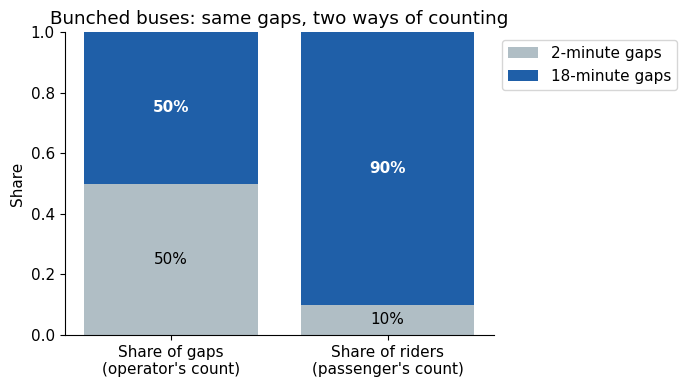

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Share of gaps\n(operator's count)", "Share of riders\n(passenger's count)"]
short_share = [0.5, 2 / 20]
long_share = [0.5, 18 / 20]
ax.bar(labels, short_share, color="#B0BEC5", label="2-minute gaps")
ax.bar(labels, long_share, bottom=short_share, color=PASSENGER, label="18-minute gaps")
for i in range(2):
    ax.text(i, short_share[i] / 2, f"{short_share[i]:.0%}", ha="center", va="center")
    ax.text(i, short_share[i] + long_share[i] / 2, f"{long_share[i]:.0%}",
            ha="center", va="center", color="white", fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Share")
ax.set_title("Bunched buses: same gaps, two ways of counting")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(False)
plt.tight_layout()
plt.show()

**Why agencies "hold" buses.** If you are on a bus that waits at a stop for no obvious reason, it may be holding to even out the gaps. That feels inefficient to the people on board, but by shrinking $\sigma$ it cuts the average wait for everyone further down the route.

## 7. The Boston MBTA Red Line (slides 23 and 24)

Allen Downey's *Probably Overthinking It* (Chapter 2) analyzes real arrival times for the Red Line in Boston during the 4:00 to 5:00 p.m. window. The slides report these summary statistics:

| | Value |
|---|---|
| Trains | 70 |
| Shortest gap | 3 minutes |
| Longest gap | 15 minutes |
| Average gap (operator's view) | 7.8 minutes |
| Average gap as seen by passengers (simulated) | 9.2 minutes |

(An average gap of 7.8 minutes means fewer than eight trains per hour, so 70 trains must come from several afternoons.)

**About the data in this notebook.** The original dataset is not bundled here, so the cell below uses a **synthetic stand-in**: 70 made-up gaps constructed to match the summary statistics above (same count, minimum, maximum, operator's average and passenger-view average). The shape will not exactly match Downey's data. In particular the slides describe the real distribution as more sharply peaked than a normal curve, and our stand-in may not be. But every comparison in this section depends only on the mean and variance, so the conclusions carry over.

If you have the real gaps (for example from Downey's book materials), you can replace the array with them using the commented lines at the end of the cell; every cell after this one will then use the real data.

In [9]:
# Synthetic stand-in for the Red Line gaps (minutes). Constructed to match the slide's
# summary statistics; NOT the original MBTA data.
gaps = np.array([
    3.0, 5.5, 9.7, 5.9, 4.5, 12.8, 4.1, 4.6, 8.4, 4.9, 9.5, 8.0, 13.4, 5.2, 9.6, 8.0,
    9.3, 11.6, 6.2, 6.9, 3.4, 4.8, 4.3, 9.8, 10.2, 7.9, 5.3, 3.7, 7.8, 14.2, 3.8, 4.4,
    11.3, 13.0, 5.9, 13.0, 15.0, 9.9, 6.6, 8.3, 6.8, 4.3, 4.5, 11.3, 6.4, 14.5, 4.3, 6.1,
    3.6, 8.2, 3.5, 6.9, 13.9, 5.5, 5.9, 6.5, 7.6, 4.1, 10.0, 8.7, 13.6, 4.3, 14.9, 7.1,
    7.9, 12.4, 5.9, 6.7, 5.5, 10.3,
])

# To use real data instead, put one gap per row in a CSV file with a column named "gap":
# import pandas as pd
# gaps = pd.read_csv("redline_gaps.csv")["gap"].to_numpy(dtype=float)

print(f"Number of trains (gaps): {gaps.size}")
print(f"Shortest gap:            {gaps.min():.1f} min")
print(f"Longest gap:             {gaps.max():.1f} min")
print(f"Average gap (operator):  {operator_mean_gap(gaps):.1f} min")
print(f"Standard deviation:      {gaps.std():.2f} min")
print(f"Average gap (passenger): {rider_mean_gap(gaps):.1f} min")

Number of trains (gaps): 70
Shortest gap:            3.0 min
Longest gap:             15.0 min
Average gap (operator):  7.8 min
Standard deviation:      3.33 min
Average gap (passenger): 9.2 min


### 7.1 The operator's view (slide 23)

First, the distribution the MBTA would report: **each gap counted once**.

We draw it as a smooth curve using a **kernel density estimate (KDE)**. A KDE places a small bump over each data point and adds the bumps together. It's a smoothed histogram. The vertical axis is **density**: the area under the curve over a range of gap lengths is the share of gaps in that range, and the total area is 1. The thin tick marks along the bottom (a "rug") show the individual gaps.

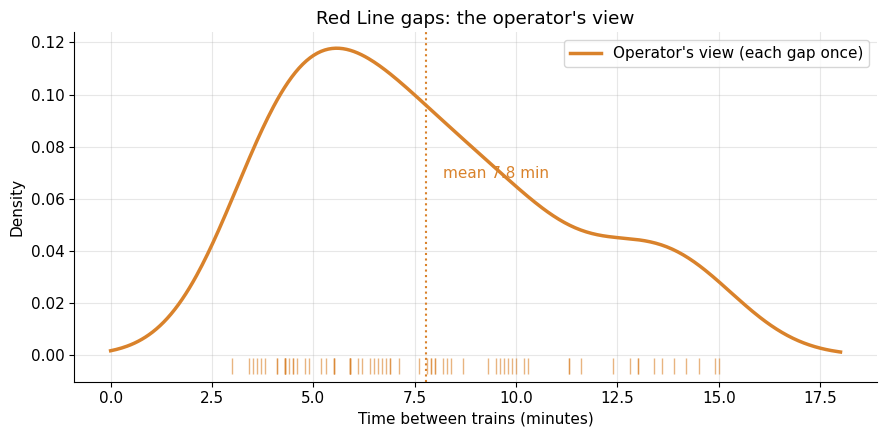

In [10]:
xs = np.linspace(0, 18, 400)
operator_kde = gaussian_kde(gaps)

fig, ax = plt.subplots()
ax.plot(xs, operator_kde(xs), color=OPERATOR, lw=2.5, label="Operator's view (each gap once)")
ax.plot(gaps, np.full_like(gaps, -0.004), "|", color=OPERATOR, ms=12, alpha=0.6)
ax.axvline(operator_mean_gap(gaps), color=OPERATOR, ls=":", lw=1.5)
ax.text(operator_mean_gap(gaps) + 0.4, ax.get_ylim()[1] * 0.55,
        f"mean {operator_mean_gap(gaps):.1f} min", color=OPERATOR)
ax.set_xlabel("Time between trains (minutes)")
ax.set_ylabel("Density")
ax.set_title("Red Line gaps: the operator's view")
ax.legend()
plt.tight_layout()
plt.show()

### 7.2 The passenger's view (slide 24)

Now the same trains, seen from the platform. A passenger who arrives at a random time lands in a gap with probability proportional to its length, so a 15-minute gap is **five times** as likely to be experienced as a 3-minute gap.

To draw the passenger's distribution, we keep exactly the same 70 gaps and give each one a **weight equal to its length** in the KDE (`weights=gaps`). That is the $x\,f(x)$ from Section 5, applied to data.

Passengers experience an average gap 18% longer than the MBTA reports.


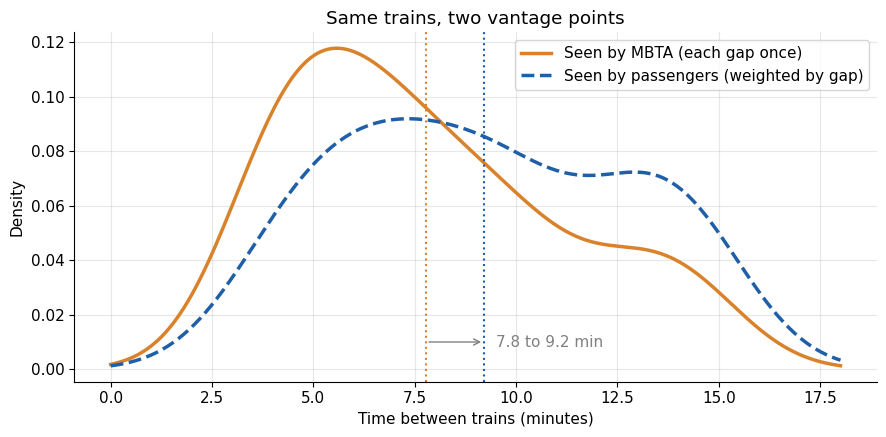

In [11]:
passenger_kde = gaussian_kde(gaps, weights=gaps)

fig, ax = plt.subplots()
ax.plot(xs, operator_kde(xs), color=OPERATOR, lw=2.5, label="Seen by MBTA (each gap once)")
ax.plot(xs, passenger_kde(xs), color=PASSENGER, lw=2.5, ls="--", label="Seen by passengers (weighted by gap)")
for value, color in [(operator_mean_gap(gaps), OPERATOR), (rider_mean_gap(gaps), PASSENGER)]:
    ax.axvline(value, color=color, ls=":", lw=1.5)
ax.annotate("", xy=(rider_mean_gap(gaps), 0.01), xytext=(operator_mean_gap(gaps), 0.01),
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.text(rider_mean_gap(gaps) + 0.3, 0.01,
        f"{operator_mean_gap(gaps):.1f} to {rider_mean_gap(gaps):.1f} min",
        ha="left", va="center", color="gray")
ax.set_xlabel("Time between trains (minutes)")
ax.set_ylabel("Density")
ax.set_title("Same trains, two vantage points")
ax.legend()
plt.tight_layout()
plt.show()

increase = rider_mean_gap(gaps) / operator_mean_gap(gaps) - 1
print(f"Passengers experience an average gap {increase:.0%} longer than the MBTA reports.")

**How to read this.** The passenger curve (dashed blue) is shifted to the right: short gaps are under-represented and long gaps over-represented. The average experienced gap rises from 7.8 to about 9.2 minutes, roughly 18% longer (the slide rounds this to "about 20%").

**Nobody is lying.** 7.8 minutes is a correct average over **gaps**; 9.2 minutes is a correct average over **passengers**. A commuter who says "the train takes longer than they claim" is reporting their experience accurately. The two numbers answer different questions:

* *"How often do we run trains?"* is a scheduling question, so it uses the operator's view.
* *"How long do our riders wait?"* is a rider-experience question, so it uses the passenger's view.

## 8. Check it by simulation

The weighted curve is a calculation. Let's confirm it the "brute force" way. We lay the 70 gaps end to end (in random order, repeated 50 times to get a long timeline), send 200,000 riders to the platform at random times, and record:

* the gap each rider landed in, and
* how long each rider waited.

If the theory is right, the simulated riders' gaps should average about 9.2 minutes, and their waits should average half of that, about 4.6 minutes. A naive rider who believed the operator's 7.8-minute figure would expect to wait 3.9 minutes.

Average gap riders landed in: simulated 9.21 min, formula 9.21 min
Average wait:                 simulated 4.61 min, formula 4.60 min
Naive expectation (half of the operator's average gap): 3.89 min


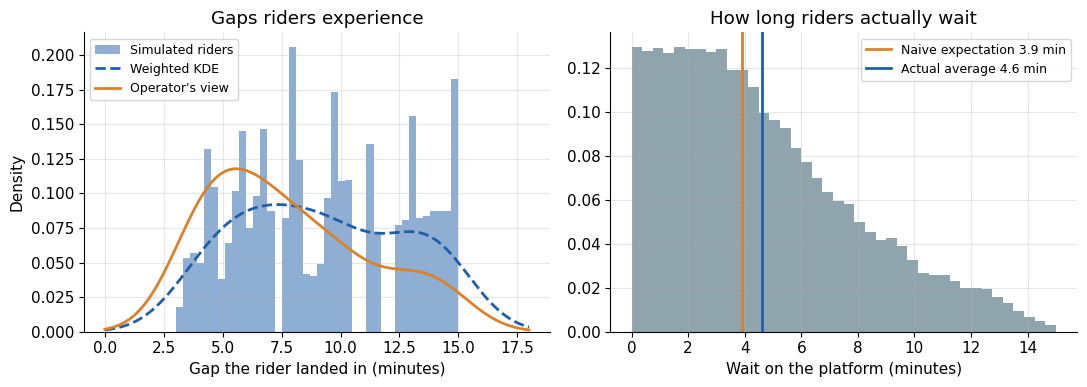

In [12]:
timeline = rng.permutation(np.tile(gaps, 50))          # 3,500 gaps in random order
buses = bus_times_from_gaps(timeline)
sim_waits, sim_seen = waits_and_gaps(buses, random_riders(buses, 200_000))

print(f"Average gap riders landed in: simulated {sim_seen.mean():.2f} min, formula {rider_mean_gap(gaps):.2f} min")
print(f"Average wait:                 simulated {sim_waits.mean():.2f} min, formula {expected_wait(gaps):.2f} min")
print(f"Naive expectation (half of the operator's average gap): {operator_mean_gap(gaps)/2:.2f} min")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(sim_seen, bins=40, density=True, color=PASSENGER, alpha=0.5, label="Simulated riders")
axes[0].plot(xs, passenger_kde(xs), color=PASSENGER, lw=2, ls="--", label="Weighted KDE")
axes[0].plot(xs, operator_kde(xs), color=OPERATOR, lw=2, label="Operator's view")
axes[0].set_xlabel("Gap the rider landed in (minutes)")
axes[0].set_ylabel("Density")
axes[0].set_title("Gaps riders experience")
axes[0].legend(fontsize=9)

axes[1].hist(sim_waits, bins=40, density=True, color="#90A4AE")
axes[1].axvline(operator_mean_gap(gaps) / 2, color=OPERATOR, lw=2, label=f"Naive expectation {operator_mean_gap(gaps)/2:.1f} min")
axes[1].axvline(sim_waits.mean(), color=PASSENGER, lw=2, label=f"Actual average {sim_waits.mean():.1f} min")
axes[1].set_xlabel("Wait on the platform (minutes)")
axes[1].set_title("How long riders actually wait")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

**How to read this.** On the left, the histogram of simulated riders lines up with the weighted (dashed) curve, not the operator's curve: the weighting in Section 7.2 really does describe what random riders experience. (The histogram is spiky because the simulated timeline reuses the same 70 gap lengths, so riders can only land in gaps of those exact lengths.) On the right, the average wait is noticeably longer than the naive expectation of half the published average gap.

Notice the shape of the wait histogram. Short waits are the most common, and long waits become steadily rarer. That's because every gap, long or short, contributes short possible waits, but only long gaps contribute long ones.

## 9. Undoing the bias: reweighting by 1/x

Suppose the MBTA had no arrival logs and instead **surveyed riders**, asking each one how long the gap was between their train and the previous one. That survey would give a length-biased sample: the passenger's view.

Exactly as with class sizes (slide 20), we can recover the operator's view by giving each rider's report a weight of $1/x$, where $x$ is the gap they reported. A 15-minute report gets one-fifth the weight of a 3-minute report, which cancels the five-times over-representation.

With weights of $1/x$, the corrected average gap becomes

$$\hat{\mu} = \frac{\sum_i x_i \cdot (1/x_i)}{\sum_i 1/x_i} = \frac{n}{\sum_i 1/x_i},$$

which is the **harmonic mean** of the reported gaps. Below we simulate a survey of 2,000 riders and compare the naive average, the corrected average and the truth.

Naive average of the survey:       9.17 min  (biased upward)
Corrected (weights 1/x):           7.77 min
True operator's average:           7.78 min


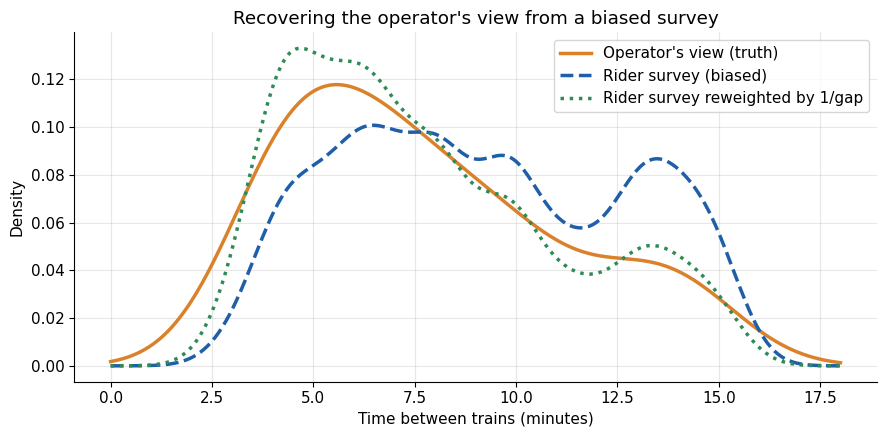

In [13]:
survey = rng.choice(sim_seen, size=2_000, replace=False)   # 2,000 riders' reported gaps

naive_mean = survey.mean()
corrected_mean = survey.size / np.sum(1 / survey)          # harmonic mean
print(f"Naive average of the survey:       {naive_mean:.2f} min  (biased upward)")
print(f"Corrected (weights 1/x):           {corrected_mean:.2f} min")
print(f"True operator's average:           {operator_mean_gap(gaps):.2f} min")

corrected_kde = gaussian_kde(survey, weights=1 / survey)
fig, ax = plt.subplots()
ax.plot(xs, operator_kde(xs), color=OPERATOR, lw=2.5, label="Operator's view (truth)")
ax.plot(xs, gaussian_kde(survey)(xs), color=PASSENGER, lw=2.5, ls="--", label="Rider survey (biased)")
ax.plot(xs, corrected_kde(xs), color=CORRECTED, lw=2.5, ls=":", label="Rider survey reweighted by 1/gap")
ax.set_xlabel("Time between trains (minutes)")
ax.set_ylabel("Density")
ax.set_title("Recovering the operator's view from a biased survey")
ax.legend()
plt.tight_layout()
plt.show()

**How to read this.** The green dotted curve, the reweighted survey, closely tracks the orange truth, and the corrected average lands close to 7.8 minutes. (It won't always match this closely: a survey of 2,000 riders has sampling noise. Try changing `size=2_000` to `size=50` and rerunning the cell to see how much the corrected estimate wobbles with a small survey.)

**The lesson from slide 20 holds here too.** Biased data is not the real danger. If you know *how* the sample was drawn (in this case, in proportion to gap length), you can correct for it. The danger is not knowing.

## 10. More variation, more waiting

The formula $E[\text{wait}] = \tfrac{1}{2}(\mu + \sigma^2/\mu)$ says the wait depends on two things: the average gap $\mu$, which the schedule controls, and the spread $\sigma$, which reliability controls.

Below we keep the average gap fixed at **10 minutes** and increase the standard deviation of the gaps from 0 to 12 minutes. The curve is the formula; the dots are simulations using gamma-distributed gaps (a flexible, always-positive distribution) with the same mean and standard deviation. Three labeled points connect to earlier sections:

* **Perfectly regular** ($\sigma = 0$): 5 minutes.
* **Bunched 2/18 pattern** ($\sigma = 8$): 8.2 minutes, from Section 6.
* **Completely random arrivals** ($\sigma = \mu = 10$, an exponential distribution): the average wait equals the **full average gap**, 10 minutes. If buses arrived with no schedule at all, you'd expect to wait as long as the average time *between* buses. This surprising case is the classic version of the waiting-time paradox.

sigma =  2.0 min:  formula  5.20 min,  simulated  5.18 min
sigma =  4.0 min:  formula  5.80 min,  simulated  5.84 min
sigma =  6.0 min:  formula  6.80 min,  simulated  6.83 min
sigma =  8.0 min:  formula  8.20 min,  simulated  8.24 min
sigma = 10.0 min:  formula 10.00 min,  simulated 10.14 min
sigma = 12.0 min:  formula 12.20 min,  simulated 12.38 min


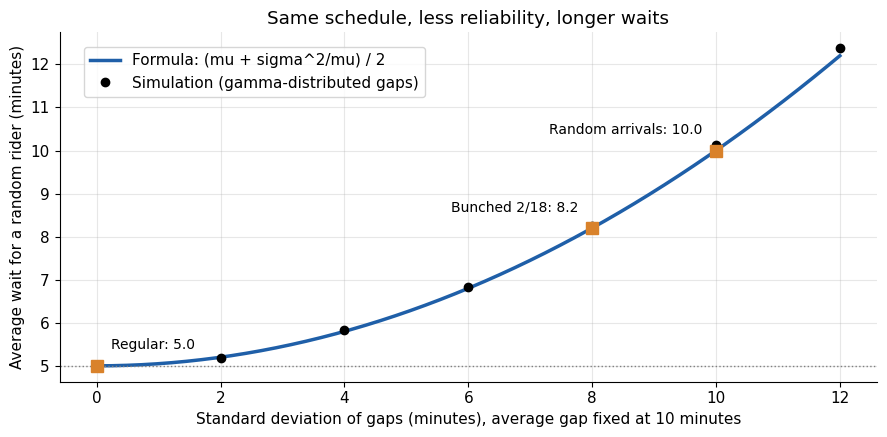

In [14]:
mu = 10.0
sigmas = np.linspace(0, 12, 200)
formula_wait = 0.5 * (mu + sigmas**2 / mu)

sim_sigmas = np.array([2, 4, 6, 8, 10, 12], dtype=float)
sim_wait = []
for s in sim_sigmas:
    shape, scale = (mu / s) ** 2, s**2 / mu          # gamma with mean mu and sd s
    g = rng.gamma(shape, scale, size=20_000)
    b = bus_times_from_gaps(g)
    w, _ = waits_and_gaps(b, random_riders(b, 100_000))
    sim_wait.append(w.mean())

fig, ax = plt.subplots()
ax.plot(sigmas, formula_wait, color=PASSENGER, lw=2.5, label="Formula: (mu + sigma^2/mu) / 2")
ax.plot(sim_sigmas, sim_wait, "o", color="black", label="Simulation (gamma-distributed gaps)")
for s, label, dx, ha in [(0, "Regular: 5.0", 10, "left"), (8, "Bunched 2/18: 8.2", -10, "right"),
                         (10, "Random arrivals: 10.0", -10, "right")]:
    y = 0.5 * (mu + s**2 / mu)
    ax.plot(s, y, "s", color=OPERATOR, ms=8, zorder=4)
    ax.annotate(label, (s, y), xytext=(dx, 12), textcoords="offset points", ha=ha, fontsize=10)
ax.axhline(mu / 2, color="gray", ls=":", lw=1)
ax.set_xlabel("Standard deviation of gaps (minutes), average gap fixed at 10 minutes")
ax.set_ylabel("Average wait for a random rider (minutes)")
ax.set_title("Same schedule, less reliability, longer waits")
ax.legend(loc="upper left", bbox_to_anchor=(0.02, 0.98))
plt.tight_layout()
plt.show()

for s, w in zip(sim_sigmas, sim_wait):
    print(f"sigma = {s:4.1f} min:  formula {0.5*(mu + s**2/mu):5.2f} min,  simulated {w:5.2f} min")

**How to read this.** The curve bends upward because the extra wait depends on $\sigma^2$. Small improvements in reliability matter a little; large ones matter a lot. A transit agency that publishes only "a bus every 10 minutes" hides the number that actually drives rider experience: how *variable* those 10 minutes are.

This is also why "more buses" is not the only way to cut waits. Making the existing buses more regular (holding strategies, dedicated bus lanes, all-door boarding) shrinks $\sigma$ and can reduce waits substantially without adding a single vehicle.

## 11. What real-time tracking changes

Slide 22 notes that real-time tracking lets riders avoid long gaps. In terms of our model, an app user is **no longer a random arrival**. They can leave home so that they reach the stop shortly before a train.

Here's a simple model. An app user decides to travel at a random moment (just like everyone else), checks the app, waits at home or in the office, and arrives at the platform at most 1 minute before the next train. Their time on the platform is the smaller of their full wait and 1 minute. We vary the share of riders who use the app and measure the average **platform** wait across all riders, using the Red Line simulation from Section 8.

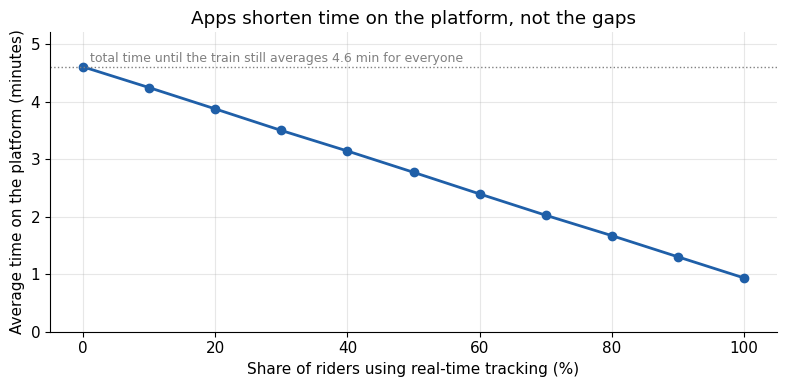

In [15]:
app_buffer = 1.0                                    # app users arrive about 1 minute early
shares = np.linspace(0, 1, 11)
platform_wait = []
for p in shares:
    uses_app = rng.random(sim_waits.size) < p
    w = np.where(uses_app, np.minimum(sim_waits, app_buffer), sim_waits)
    platform_wait.append(w.mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(shares * 100, platform_wait, "o-", color=PASSENGER, lw=2)
ax.axhline(sim_waits.mean(), color="gray", ls=":", lw=1)
ax.text(1, sim_waits.mean() + 0.08, "total time until the train still averages "
        f"{sim_waits.mean():.1f} min for everyone", color="gray", fontsize=9)
ax.set_xlabel("Share of riders using real-time tracking (%)")
ax.set_ylabel("Average time on the platform (minutes)")
ax.set_title("Apps shorten time on the platform, not the gaps")
ax.set_ylim(0, sim_waits.mean() + 0.6)
plt.tight_layout()
plt.show()

**How to read this.** As more riders use the app, average time spent **on the platform** falls sharply. But look at what has not changed: the trains, the gaps, and the total time between deciding to travel and boarding. App users still "wait"; they just do it somewhere more comfortable and with less uncertainty.

That's a context point worth noticing. The app changes the rider's **experience** of the same service. A survey of riders on the platform would now show shorter waits even though the operator's reliability is identical, a new way for the two vantage points to diverge. And the benefit goes to riders who have a smartphone, a data plan and the habit of checking, which raises the access questions from the 3D-scan example on slide 7.

## 12. Exercises

Try to **predict** each answer with the formula before you run any code.

1. **A milder bunching pattern.** Change the bunched gaps in Section 6 from 2/18 to 4/16. What is the expected wait? How much of the 64% increase disappears?
   *Hint:* $E[X^2] = (4^2 + 16^2)/2$.

2. **A reliability target.** The average gap stays at 10 minutes. What standard deviation would keep the average wait at 6 minutes or less? Solve $\tfrac{1}{2}(10 + \sigma^2/10) = 6$, then check your answer by simulation using the gamma code in Section 10.

3. **Fewer buses or more regular ones?** Compare two options: (a) buses every 8 minutes on average, but with $\sigma = 6$; (b) buses every 10 minutes on average, perfectly regular. Which gives the shorter average wait? What does that suggest about how transit performance should be measured?

4. **Your own data.** Record the arrival times of a bus or shuttle you use for a few days (or find a city's open transit data). Compute the operator's average gap and the passenger's average gap with `operator_mean_gap` and `rider_mean_gap`. How big is the paradox on your route?

5. **Which number should be published?** Write a two-sentence recommendation to a transit authority: which average should it report to the public, and why? Use the idea of vantage points from the lecture.

6. **Beyond buses.** The same code works for any "random visitor lands in an interval" situation: elevators, checkout lanes, customer-service hold times (slide 34). Pick one and describe what the "gaps" and the "riders" would be.

## 13. Summary

* **Two vantage points.** The operator counts each gap once; riders arriving at random land in gaps with probability proportional to their length. Both averages are correct, and they answer different questions.
* **The formula.** Riders experience an average gap of $\mu + \sigma^2/\mu$ and wait $\tfrac{1}{2}(\mu + \sigma^2/\mu)$ on average. With no variation there is no paradox; with more variation, waits grow with the square of the spread.
* **Bunching.** Same buses, same average gap of 10 minutes, but a 2/18 pattern raises the average wait from 5.0 to 8.2 minutes.
* **The Red Line.** An operator's average gap of 7.8 minutes becomes about 9.2 minutes from the platform.
* **The fix.** Weighting each rider's report by $1/x$ (equivalently, taking the harmonic mean) recovers the operator's view.
* **Technology changes context.** Real-time apps change riders' experience without changing the service, which opens a new gap between what is reported and what is experienced.

**Further reading.** Allen B. Downey, *Probably Overthinking It* (University of Chicago Press, 2023), Chapter 2, "Relay Races and Revolving Doors." In probability textbooks, look up the *waiting-time paradox* or *inspection paradox* in the context of renewal processes.